     Brand  Horsepower  Mileage_kmpl  Age_years  Engine_CC  Owner_Count  \
0     Audi         206            15         14       1126            2   
1   Toyota         207            16          8       2592            2   
2     Ford         258            23          6       2559            1   
3     Audi         187            22          3       1789            1   
4    Honda          98            17         14       1751            2   
5     Ford         188            19          9       1522            2   
6     Ford         326            18          2       2879            2   
7     Audi         210            27         11       1228            2   
8  Hyundai         158            11          8       2300            1   
9    Honda         322            14         10       1085            2   

   Price_Lakhs  
0        16.86  
1        12.02  
2         9.87  
3        20.70  
4         4.19  
5         5.54  
6        14.27  
7        19.10  
8         8.41  
9   

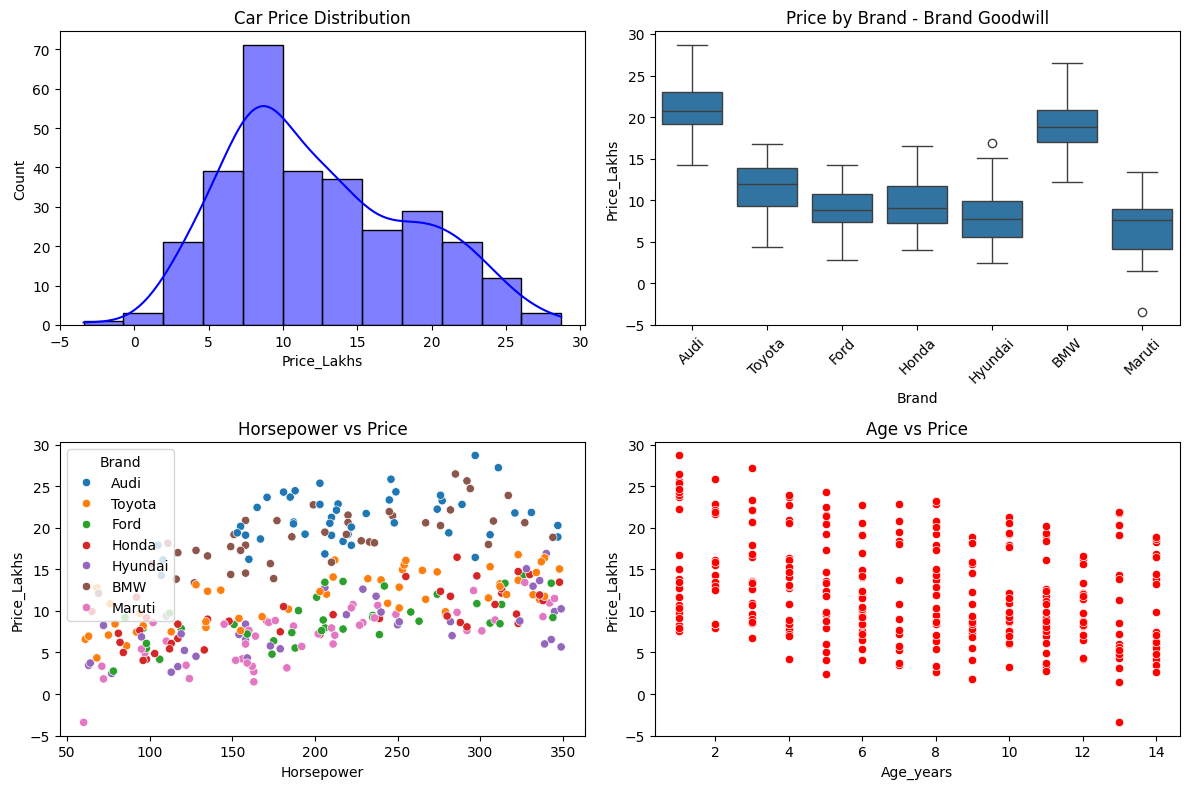

Linear Regression R2: 0.6698
Random Forest R2: 0.9290
MAE: 1.4080


/tmp/ipykernel_1793/1020972143.py:81: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=importance, palette='viridis')


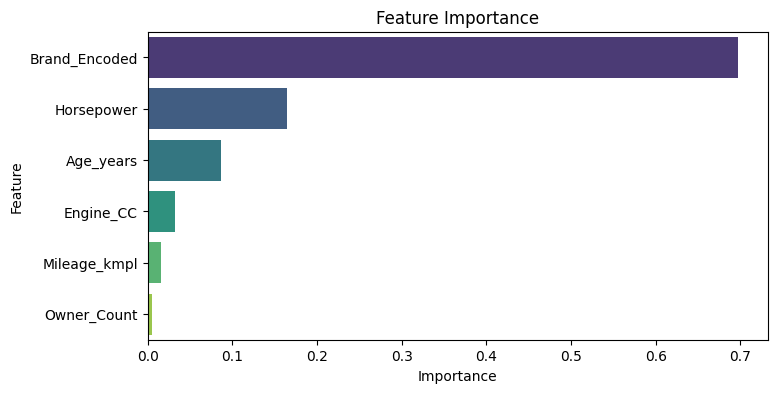

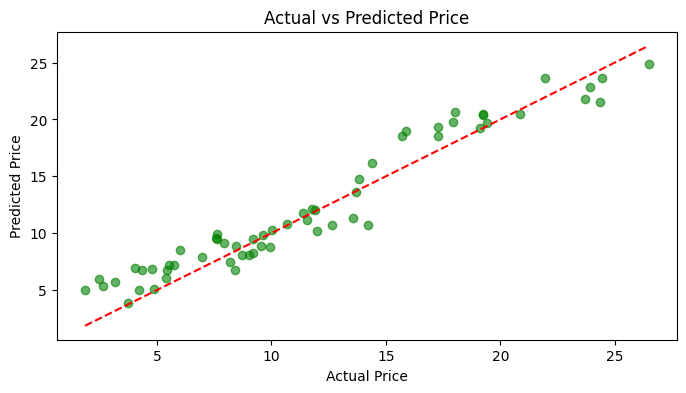

Key Insights: Brand goodwill & Horsepower increase price, Age decreases price


In [1]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Create Car Dataset
np.random.seed(42)
n = 300
brands = np.random.choice(['Maruti', 'Hyundai', 'Honda', 'Toyota', 'Ford', 'BMW', 'Audi'], n)
horsepower = np.random.randint(60, 350, n)
mileage = np.random.randint(10, 30, n)
age = np.random.randint(1, 15, n)
engine_cc = np.random.randint(800, 3000, n)
owner = np.random.randint(1, 3, n)

brand_value = {'Maruti':1, 'Hyundai':2, 'Honda':3, 'Toyota':4, 'Ford':2, 'BMW':8, 'Audi':9}
brand_score = [brand_value[b] for b in brands]
price = (np.array(brand_score)*1.5 + horsepower*0.02 - age*0.4 - mileage*0.05 + engine_cc*0.001 + np.random.normal(0,1,n)) * 1.2 + 2

df = pd.DataFrame({
    'Brand': brands,
    'Horsepower': horsepower,
    'Mileage_kmpl': mileage,
    'Age_years': age,
    'Engine_CC': engine_cc,
    'Owner_Count': owner,
    'Price_Lakhs': np.round(price,2)
})
print(df.head(10))
print("Shape:", df.shape)

# Visualization 1
plt.figure(figsize=(12,8))
plt.subplot(2,2,1)
sns.histplot(df['Price_Lakhs'], kde=True, color='blue')
plt.title('Car Price Distribution')

plt.subplot(2,2,2)
sns.boxplot(x='Brand', y='Price_Lakhs', data=df)
plt.xticks(rotation=45)
plt.title('Price by Brand - Brand Goodwill')

plt.subplot(2,2,3)
sns.scatterplot(x='Horsepower', y='Price_Lakhs', hue='Brand', data=df)
plt.title('Horsepower vs Price')

plt.subplot(2,2,4)
sns.scatterplot(x='Age_years', y='Price_Lakhs', data=df, color='red')
plt.title('Age vs Price')
plt.tight_layout()
plt.show()

# Preprocessing
le = LabelEncoder()
df['Brand_Encoded'] = le.fit_transform(df['Brand'])
X = df[['Brand_Encoded', 'Horsepower', 'Mileage_kmpl', 'Age_years', 'Engine_CC', 'Owner_Count']]
y = df['Price_Lakhs']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Model 1 - Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)
print(f"Linear Regression R2: {r2_score(y_test, y_pred_lr):.4f}")

# Model 2 - Random Forest (Better)
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
print(f"Random Forest R2: {r2_score(y_test, y_pred_rf):.4f}")
print(f"MAE: {mean_absolute_error(y_test, y_pred_rf):.4f}")

# Feature Importance
importance = pd.DataFrame({'Feature': X.columns, 'Importance': rf.feature_importances_}).sort_values('Importance', ascending=False)
plt.figure(figsize=(8,4))
sns.barplot(x='Importance', y='Feature', data=importance, palette='viridis')
plt.title('Feature Importance')
plt.show()

# Final Prediction Graph
plt.figure(figsize=(8,4))
plt.scatter(y_test, y_pred_rf, alpha=0.6, color='green')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('Actual vs Predicted Price')
plt.show()

print("Key Insights: Brand goodwill & Horsepower increase price, Age decreases price")